# Work dates
How many individuals can be placed in time by the dates of their works, and in which centuries. Works only, taken from notebook 15; Wikidata values only.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

FIRST_CENTURY = -1000
LAST_CENTURY = 2000
PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(80)

SERIES_COLORS = {
    'At least 2 precise works': BLUE,
    'Only 1 precise work': LIGHT_BLUE,
    'At least one work with a precise date': NAVY,
}

apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)

## Load the data
A work's date is its publication date, else its inception, as for `works_period`. A decade-precise date is moved to the middle of its decade. Each individual gets one row: dated works, precise dated works, earliest precise work year.

In [2]:
works = connection.execute('''
    WITH dated AS (
        SELECT individual_work.qid,
               individual_work.work_qid,
               coalesce(work.publication_date.year, work.inception.year) AS year,
               CASE WHEN work.publication_date.year IS NOT NULL THEN work.publication_date.precision
                    ELSE work.inception.precision END AS precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE coalesce(work.publication_date.year, work.inception.year) IS NOT NULL
    )
    SELECT qid,
           count(DISTINCT work_qid) AS dated_works,
           count(DISTINCT work_qid) FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS precise_works,
           min(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END)
               FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS first_precise_year
    FROM dated
    GROUP BY qid
''').pl()
print(f'{len(works):,} individuals with at least one dated work')
works.sample(5, seed=0)

2,780,765 individuals with at least one dated work


qid,dated_works,precise_works,first_precise_year
str,i64,i64,i64
"""Q92677358""",1,1,2020
"""Q91068932""",3,3,2014
"""Q19921952""",8,8,1906
"""Q113018388""",24,24,2020
"""Q56809311""",24,24,2000


In [3]:
def by_century(frame, year_column):
    in_range = frame.with_columns((pl.col(year_column) // 100 * 100).alias('century_start')).filter(
        pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY))
    print(f'{frame.height - in_range.height:,} individuals outside {FIRST_CENTURY}–{LAST_CENTURY + 99} or without a year left out of the table')
    return in_range.group_by('century_start').len('individuals').sort('century_start')


def plot_centuries(series, labelled=()):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    for name, frame in series.items():
        frame = frame.filter(pl.col('individuals') > 0)
        ax.plot(frame['century_start'], frame['individuals'], marker='o', markersize=5, color=SERIES_COLORS[name], label=name)
        if name in labelled:
            for x, y in zip(frame['century_start'], frame['individuals']):
                ax.annotate(f'{y:,}', (x, y), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=POINT_LABEL_FONTSIZE, color=TEXT)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_xlim(FIRST_CENTURY - 50, LAST_CENTURY + 50)
    ax.set_xticks(range(FIRST_CENTURY, LAST_CENTURY + 1, 100))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
    ax.set_xlabel('Century (start year)')
    ax.set_ylabel('Individuals (log scale)')
    ax.grid(axis='y')
    ax.legend(loc='upper left')
    plt.show()

## 1. Individuals with at least two dated works

In [4]:
two_dated = works.filter(pl.col('dated_works') >= 2)
two_precise = works.filter(pl.col('precise_works') >= 2)
print(f'{two_dated.height:,} individuals with at least 2 dated works (any precision)')
print(f'{two_precise.height:,} of them with at least 2 works dated to the year or decade')
assert two_precise.height <= two_dated.height

1,794,294 individuals with at least 2 dated works (any precision)
1,789,214 of them with at least 2 works dated to the year or decade


### By century of their first precise work

In [5]:
two_precise_century = by_century(two_precise, 'first_precise_year')
two_precise_century

7 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-900,1
-800,2
-700,2
-600,14
-500,35
-400,23
-300,7
-200,3
-100,14


### Figure: individuals with at least 2 precise works, by century

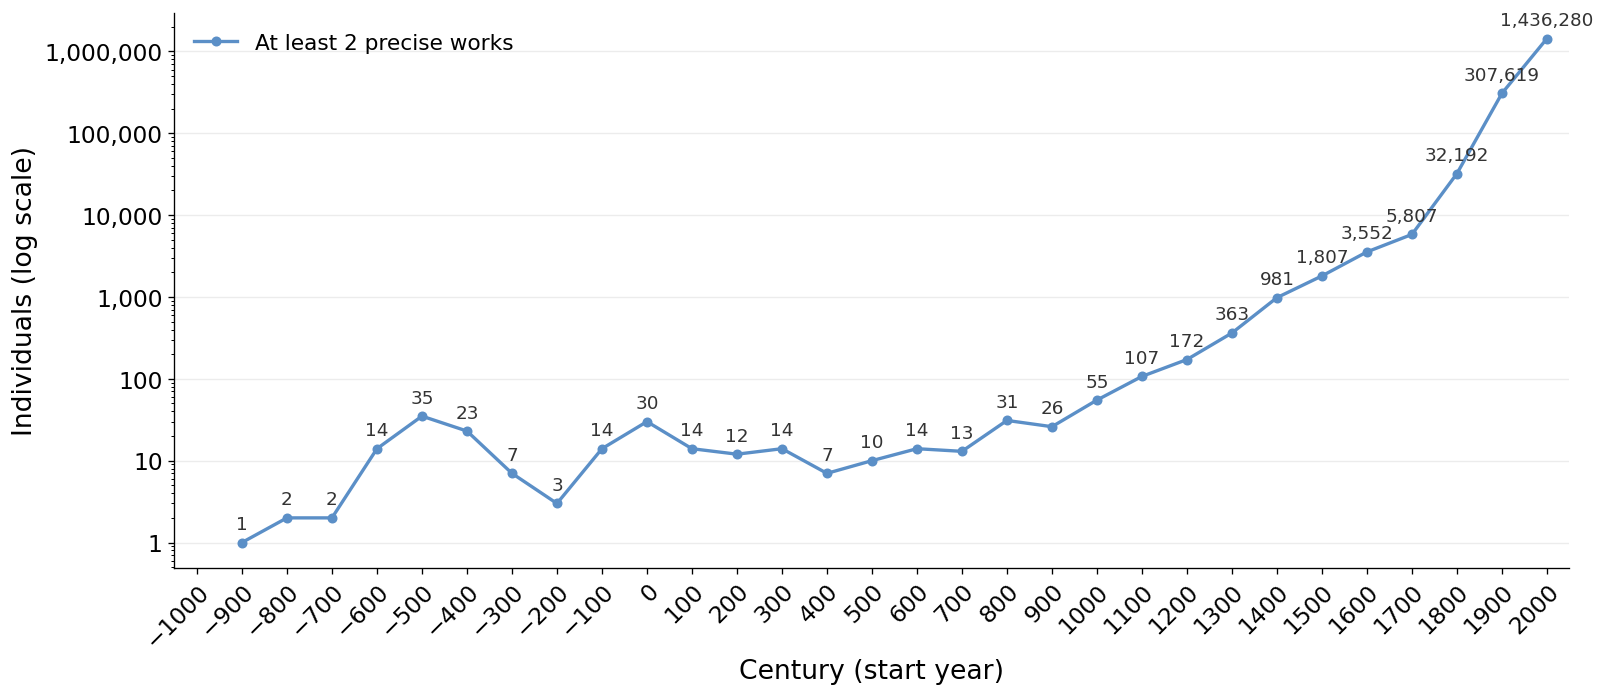

In [6]:
plot_centuries({'At least 2 precise works': two_precise_century}, labelled=['At least 2 precise works'])

### One example per century
The individual with the most Wikimedia pages among those whose first precise work falls in the century, with their two earliest precise works that have a title. Each individual and work is followed by its Wikidata id in brackets.

In [7]:
examples_input = two_precise.with_columns((pl.col('first_precise_year') // 100 * 100).alias('century_start')).filter(
    pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY)).select('qid', 'century_start')
connection.register('examples_input', examples_input.to_arrow())

30 centuries, 30 in the chart


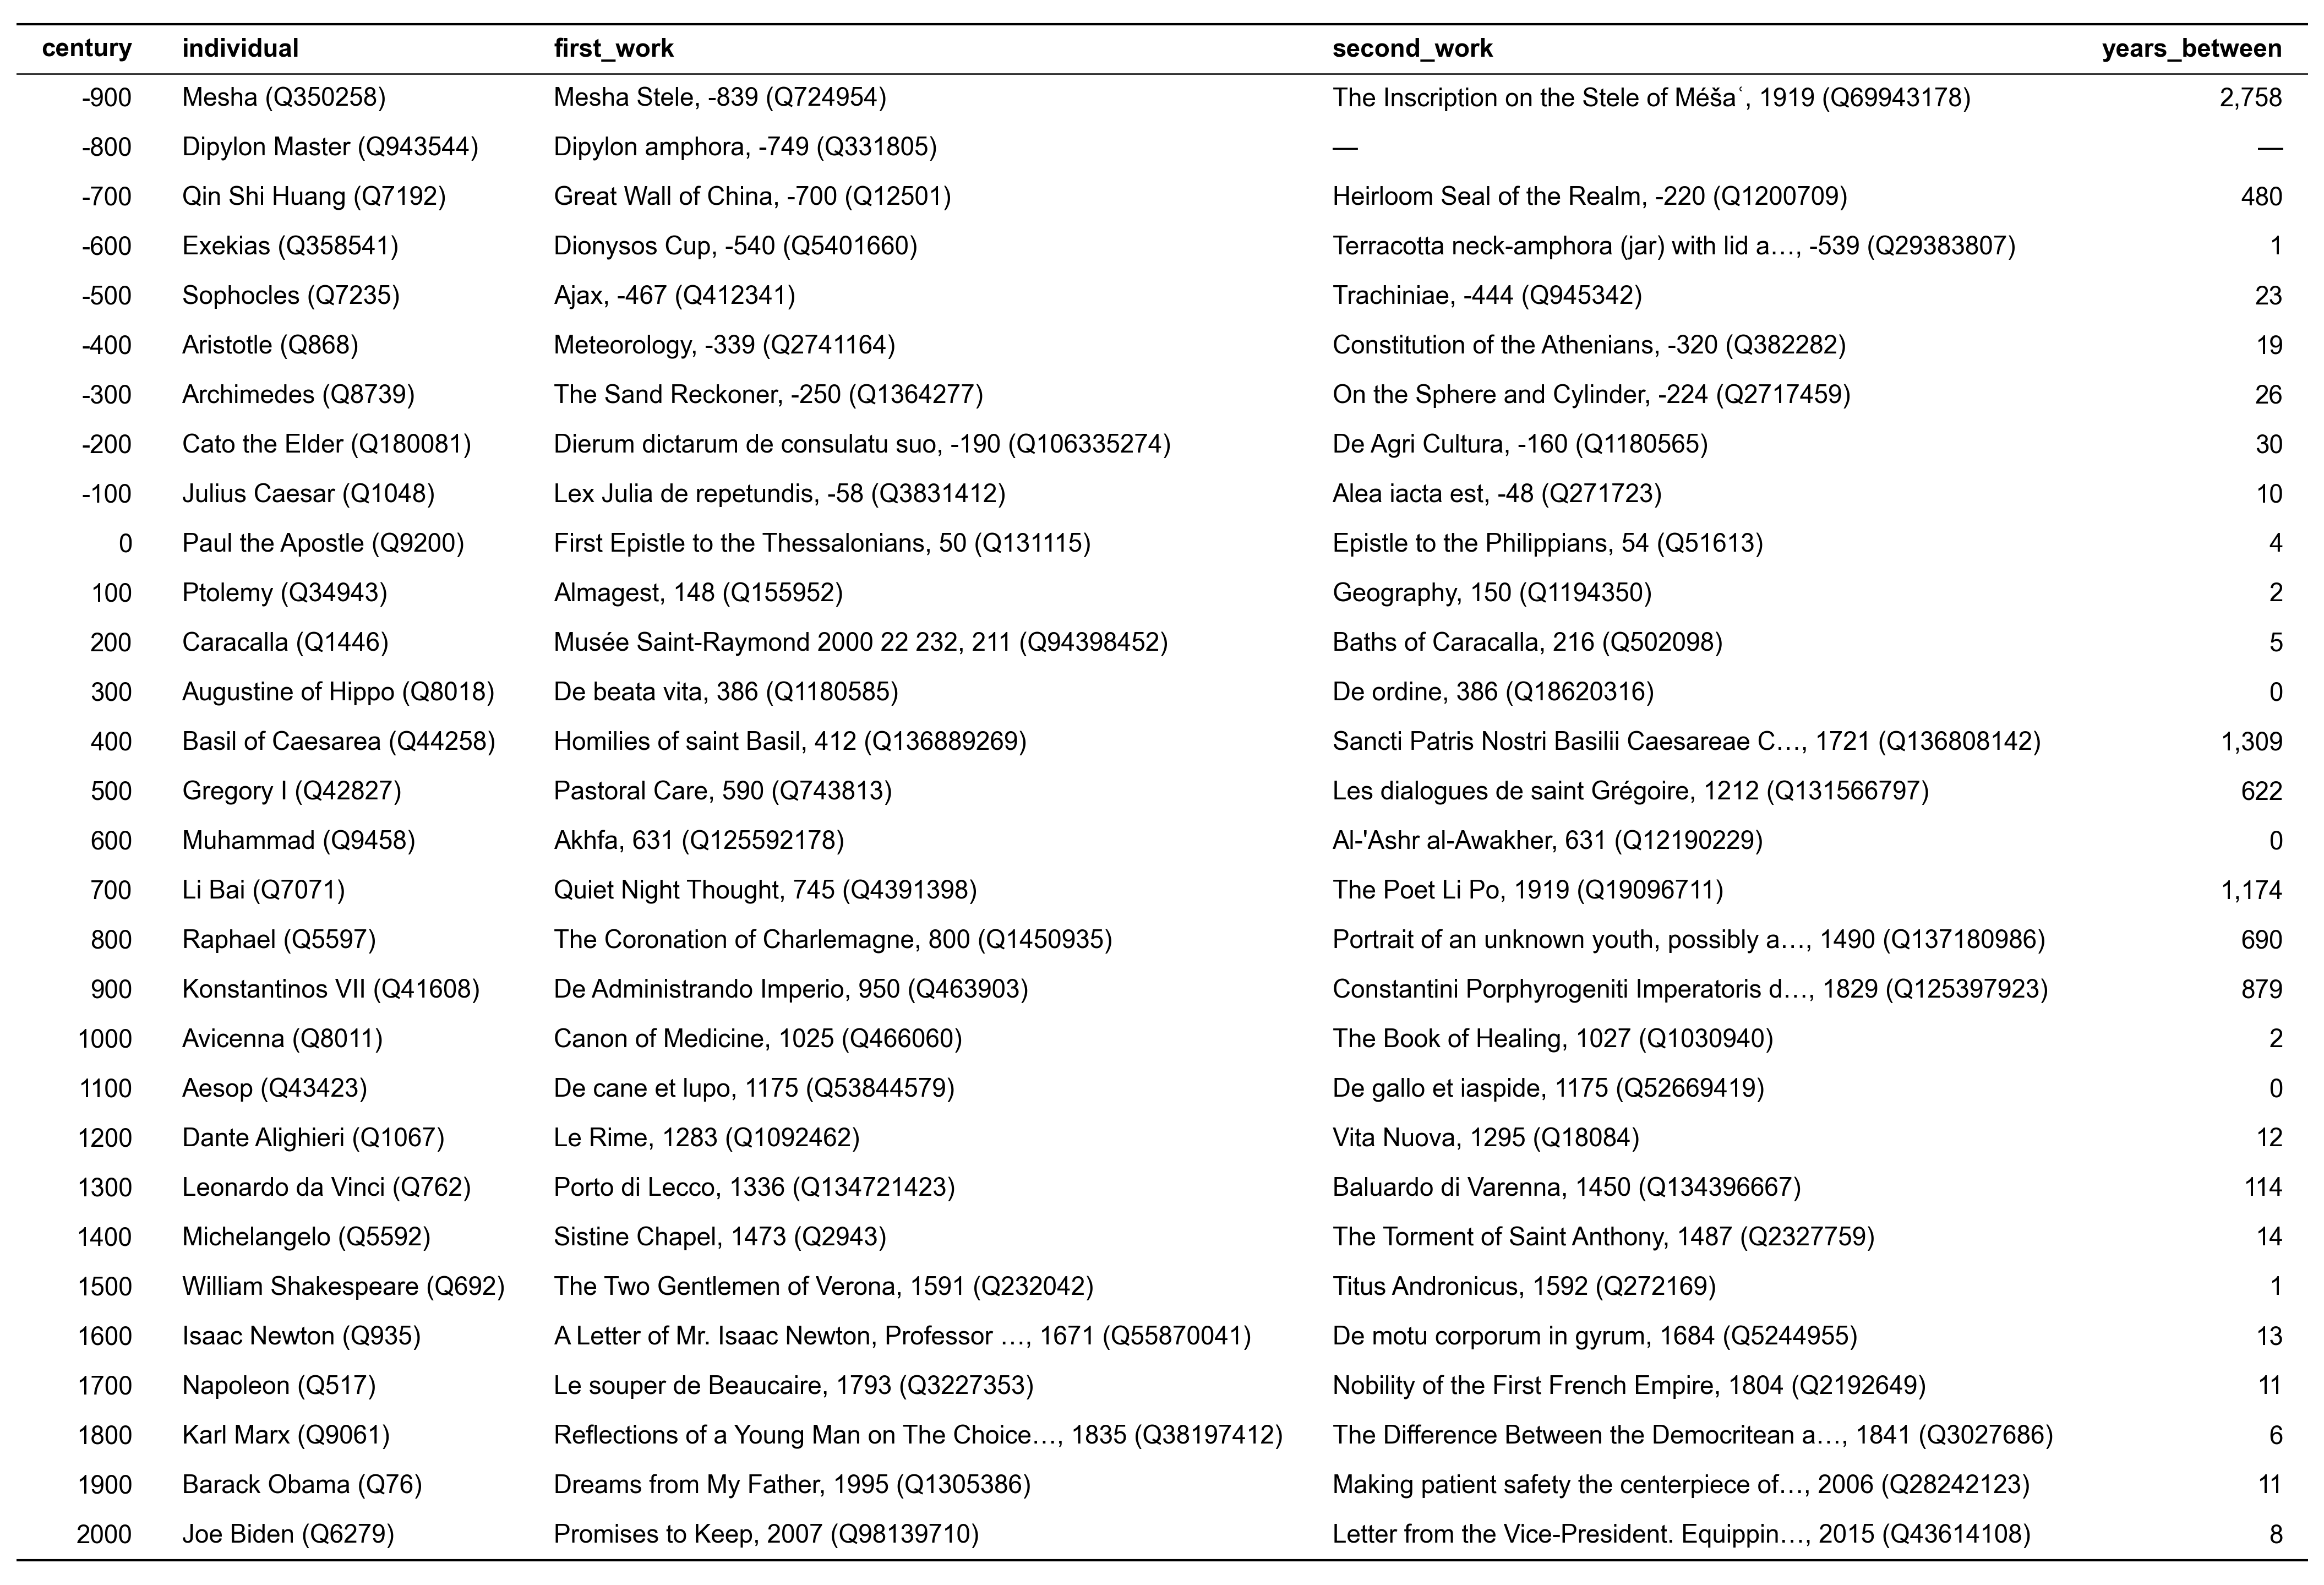

In [8]:
examples_with_ids = connection.execute('''
    WITH best AS (
        SELECT examples_input.century_start, examples_input.qid,
               coalesce(individual.entity.label_en, individual.entity.label_non_en) || ' (' || examples_input.qid || ')' AS individual
        FROM examples_input
        JOIN individual ON individual.entity.qid = examples_input.qid
        QUALIFY row_number() OVER (PARTITION BY examples_input.century_start ORDER BY len(individual.sitelink) DESC, examples_input.qid) = 1
    ),
    dated AS (
        SELECT best.century_start, best.individual, work.entity.qid AS work_qid,
               coalesce(work.entity.label_en, work.entity.label_non_en) AS work,
               coalesce(work.publication_date.year, work.inception.year) AS year,
               CASE WHEN work.publication_date.year IS NOT NULL THEN work.publication_date.precision
                    ELSE work.inception.precision END AS precision
        FROM best
        JOIN individual_work ON individual_work.qid = best.qid
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    first_two AS (
        SELECT century_start, individual, year,
               CASE WHEN length(work) > 40 THEN left(work, 40) || '…' ELSE work END || ', ' || year || ' (' || work_qid || ')' AS work,
               row_number() OVER (PARTITION BY century_start ORDER BY year, CASE WHEN length(work) > 50 THEN left(work, 50) || '…' ELSE work END || ' (' || year || ')') AS position
        FROM dated
        WHERE precision IN ('day', 'month', 'year', 'decade') AND work IS NOT NULL
        QUALIFY position <= 2
    )
    SELECT century_start AS century, individual,
           max(work) FILTER (WHERE position = 1) AS first_work,
           max(work) FILTER (WHERE position = 2) AS second_work,
           max(year) FILTER (WHERE position = 2) - max(year) FILTER (WHERE position = 1) AS years_between
    FROM first_two
    GROUP BY ALL
    ORDER BY century_start
''').pl().with_columns(pl.col('century').cast(pl.String))
print(f'{examples_with_ids.height} centuries, {two_precise_century.height} in the chart')
show_table(examples_with_ids)

### Same examples, inception dates only
As the table above, but a work's date is only its inception (P571); publication dates are ignored. The individuals are those with at least two works whose inception is precise to the year or decade, each placed at the century of their first one. Each individual and work is followed by its Wikidata id in brackets.

27 centuries with an example


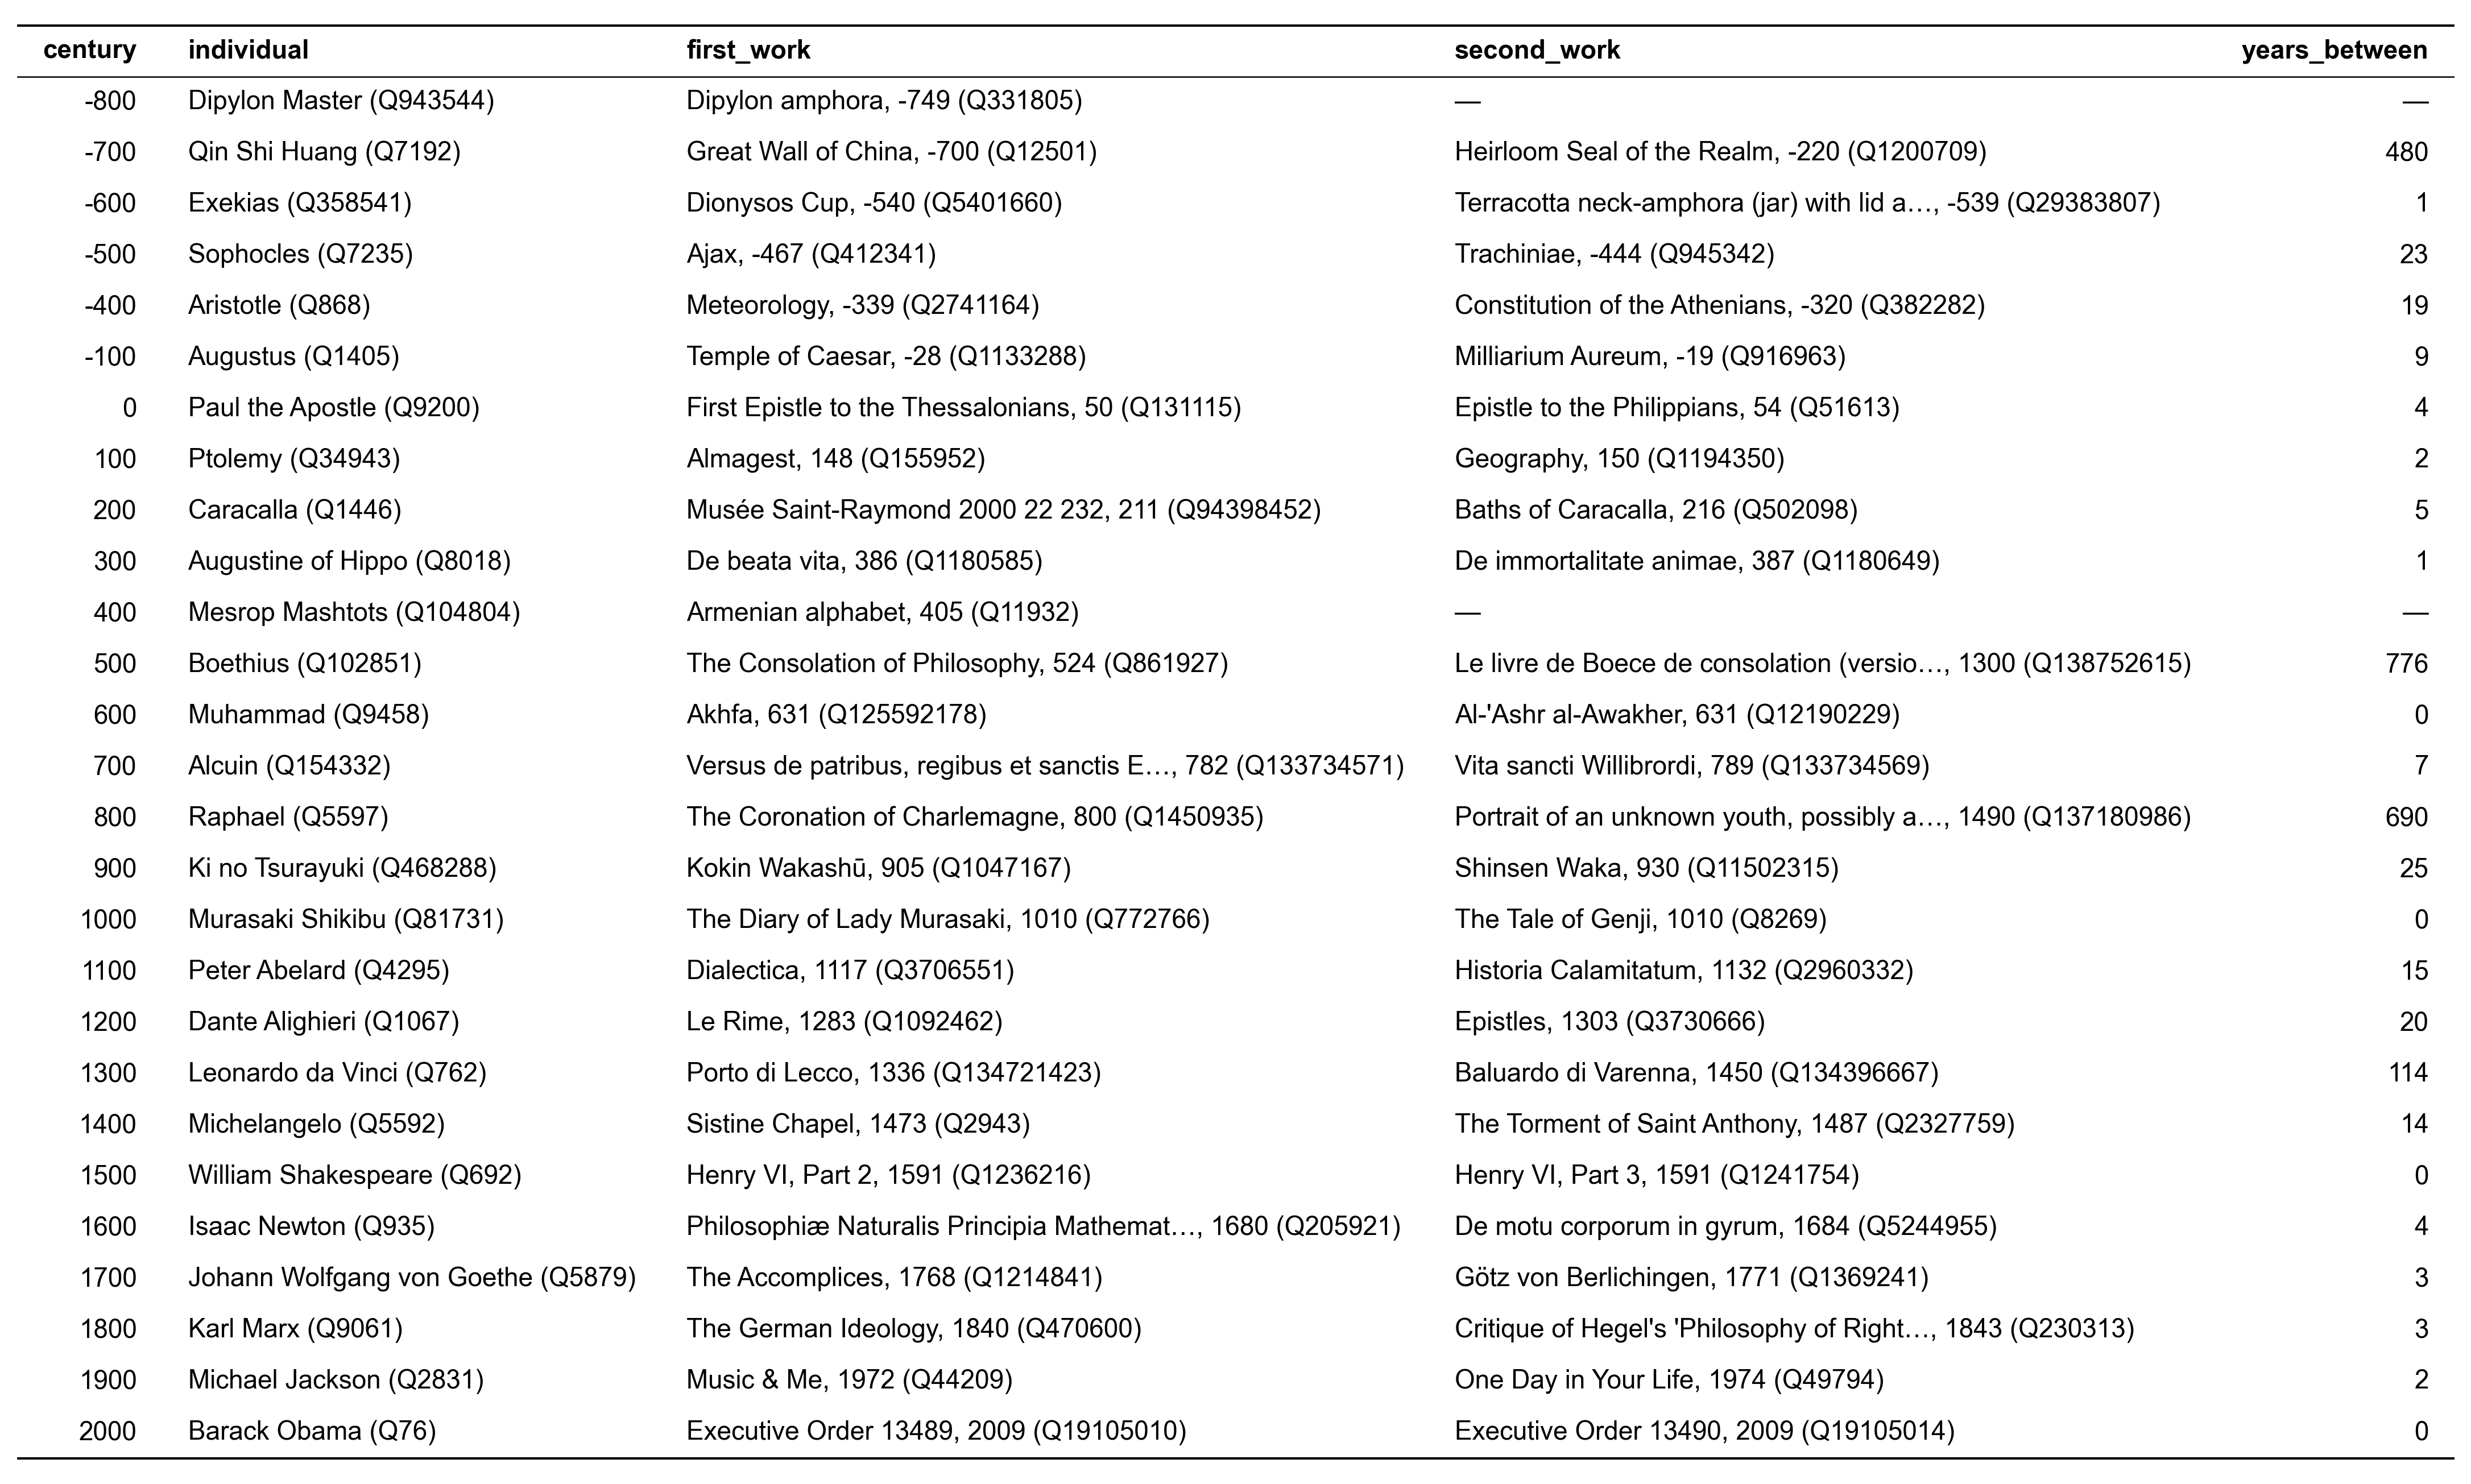

In [9]:
inception_examples = connection.execute('''
    WITH dated AS (
        SELECT individual_work.qid, work.entity.qid AS work_qid,
               coalesce(work.entity.label_en, work.entity.label_non_en) AS work,
               work.inception.year AS year,
               CASE WHEN work.inception.precision = 'decade' THEN work.inception.year + 5 ELSE work.inception.year END AS placed_year
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE work.inception.precision IN ('day', 'month', 'year', 'decade')
    ),
    candidates AS (
        SELECT qid, floor(min(placed_year) / 100)::BIGINT * 100 AS century_start
        FROM dated
        GROUP BY qid
        HAVING count(DISTINCT work_qid) >= 2
    ),
    best AS (
        SELECT candidates.century_start, candidates.qid,
               coalesce(individual.entity.label_en, individual.entity.label_non_en) || ' (' || candidates.qid || ')' AS individual
        FROM candidates
        JOIN individual ON individual.entity.qid = candidates.qid
        WHERE candidates.century_start BETWEEN {first} AND {last}
        QUALIFY row_number() OVER (PARTITION BY candidates.century_start ORDER BY len(individual.sitelink) DESC, candidates.qid) = 1
    ),
    first_two AS (
        SELECT best.century_start, best.individual, dated.year,
               CASE WHEN length(dated.work) > 40 THEN left(dated.work, 40) || '…' ELSE dated.work END || ', ' || dated.year || ' (' || dated.work_qid || ')' AS work,
               row_number() OVER (PARTITION BY best.century_start ORDER BY dated.year, dated.work) AS position
        FROM best
        JOIN dated ON dated.qid = best.qid
        WHERE dated.work IS NOT NULL
        QUALIFY position <= 2
    )
    SELECT century_start AS century, individual,
           max(work) FILTER (WHERE position = 1) AS first_work,
           max(work) FILTER (WHERE position = 2) AS second_work,
           max(year) FILTER (WHERE position = 2) - max(year) FILTER (WHERE position = 1) AS years_between
    FROM first_two
    GROUP BY ALL
    ORDER BY century_start
'''.format(first=FIRST_CENTURY, last=LAST_CENTURY)).pl().with_columns(pl.col('century').cast(pl.String))
print(f'{inception_examples.height} centuries with an example')
show_table(inception_examples)

### Table: first and second work more than a lifetime apart
For every individual with at least two works dated to the year or decade, the gap between their two earliest works. A gap over 100 years cannot come from one person's lifetime: the second work is usually a later edition, a work dated by its subject, or a wrong statement. Each row uses a different work date: publication else inception (the rule used above), publication only, inception only. "Before 1500" keeps individuals whose first precise work is before 1500.

In [10]:
GAP_LIMIT = 100
DATE_RULES = {
    'Publication, else inception': (
        'coalesce(work.publication_date.year, work.inception.year)',
        'CASE WHEN work.publication_date.year IS NOT NULL THEN work.publication_date.precision ELSE work.inception.precision END',
    ),
    'Publication only': ('work.publication_date.year', 'work.publication_date.precision'),
    'Inception only': ('work.inception.year', 'work.inception.precision'),
}


def first_two_gaps(year, precision):
    return connection.execute(f'''
        WITH dated AS (
            SELECT DISTINCT individual_work.qid, individual_work.work_qid, {year} AS year
            FROM individual_work
            JOIN work ON work.entity.qid = individual_work.work_qid
            WHERE {precision} IN ('day', 'month', 'year', 'decade')
        ),
        first_two AS (
            SELECT qid, year
            FROM dated
            QUALIFY row_number() OVER (PARTITION BY qid ORDER BY year, work_qid) <= 2
        )
        SELECT count(*) AS individuals,
               count(*) FILTER (WHERE gap > {GAP_LIMIT}) AS over_limit,
               count(*) FILTER (WHERE first_year < 1500) AS before_1500,
               count(*) FILTER (WHERE first_year < 1500 AND gap > {GAP_LIMIT}) AS before_1500_over_limit
        FROM (
            SELECT qid, min(year) AS first_year, max(year) - min(year) AS gap
            FROM first_two
            GROUP BY qid
            HAVING count(*) = 2
        )
    ''').pl()


gaps = pl.concat([first_two_gaps(*sql).with_columns(pl.lit(rule).alias('rule')) for rule, sql in DATE_RULES.items()])
gaps

individuals,over_limit,before_1500,before_1500_over_limit,rule
i64,i64,i64,i64,str
1789214,1641,1960,369,"""Publication, else inception"""
1732878,1144,640,220,"""Publication only"""
59638,363,1267,91,"""Inception only"""


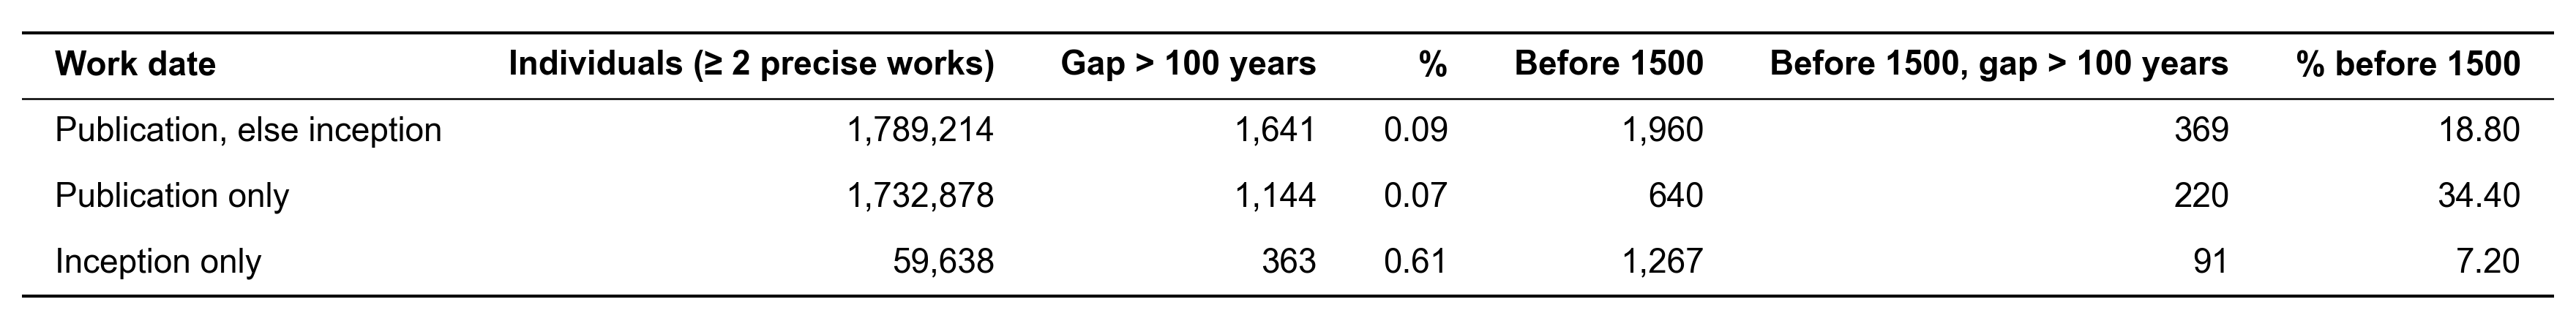

In [11]:
show_table(gaps.select(
    pl.col('rule').alias('Work date'),
    pl.col('individuals').alias('Individuals (≥ 2 precise works)'),
    pl.col('over_limit').alias(f'Gap > {GAP_LIMIT} years'),
    (100 * pl.col('over_limit') / pl.col('individuals')).round(2).alias('%'),
    pl.col('before_1500').alias('Before 1500'),
    pl.col('before_1500_over_limit').alias(f'Before 1500, gap > {GAP_LIMIT} years'),
    (100 * pl.col('before_1500_over_limit') / pl.col('before_1500')).round(1).alias('% before 1500'),
), decimals=2)

### Table: works with a precise inception or publication date, before and after 1500
Counted over every work in the database, keeping only dates precise to the day, month, year or decade. A work is placed before or after 1500 by the date of that row; for works with both dates, by the earlier of the two.

17,050,395 works in the database


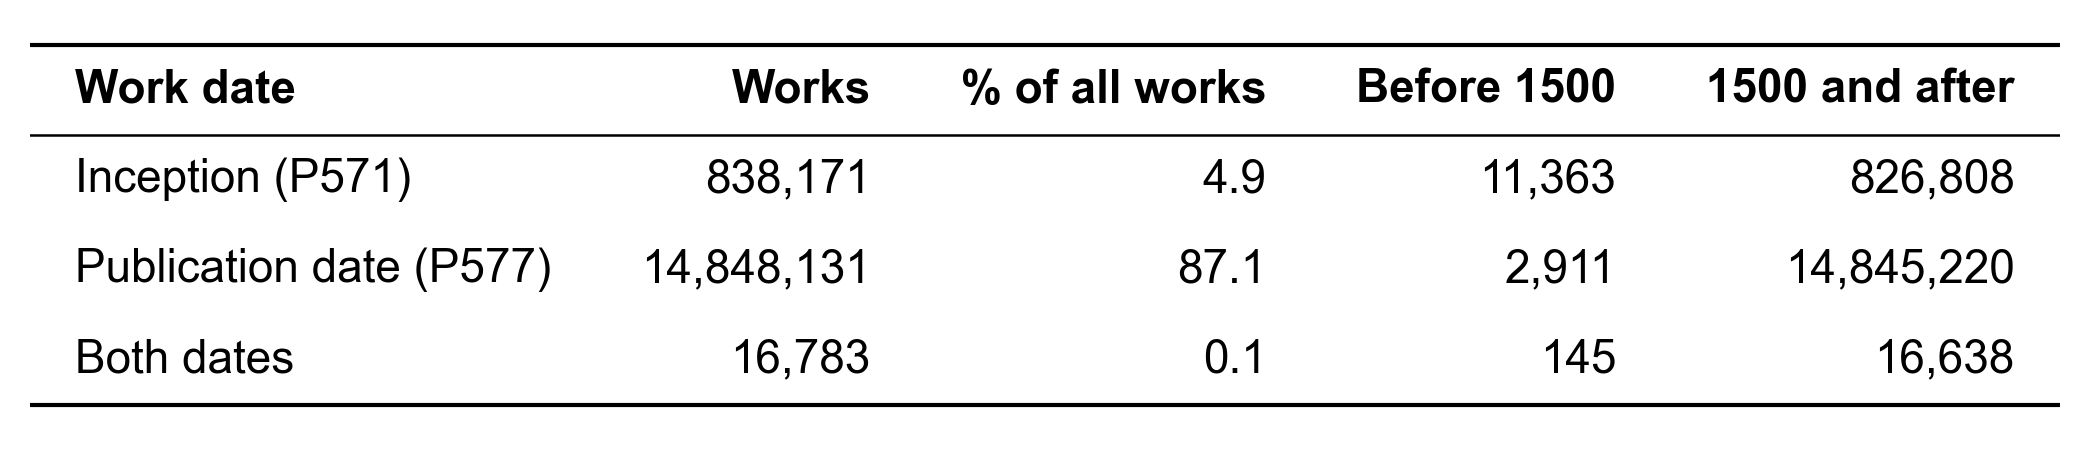

In [12]:
work_counts = connection.execute('''
    WITH dates AS (
        SELECT CASE WHEN inception.precision IN ('day', 'month', 'year', 'decade') THEN inception.year END AS inception_year,
               CASE WHEN publication_date.precision IN ('day', 'month', 'year', 'decade') THEN publication_date.year END AS publication_year
        FROM work
    )
    SELECT 'Inception (P571)' AS date,
           count(inception_year) AS works,
           count(*) FILTER (WHERE inception_year < 1500) AS before_1500,
           count(*) FILTER (WHERE inception_year >= 1500) AS from_1500
    FROM dates
    UNION ALL
    SELECT 'Publication date (P577)',
           count(publication_year),
           count(*) FILTER (WHERE publication_year < 1500),
           count(*) FILTER (WHERE publication_year >= 1500)
    FROM dates
    UNION ALL
    SELECT 'Both dates',
           count(*) FILTER (WHERE inception_year IS NOT NULL AND publication_year IS NOT NULL),
           count(*) FILTER (WHERE least(inception_year, publication_year) < 1500 AND inception_year IS NOT NULL AND publication_year IS NOT NULL),
           count(*) FILTER (WHERE least(inception_year, publication_year) >= 1500 AND inception_year IS NOT NULL AND publication_year IS NOT NULL)
    FROM dates
''').pl()
total_works = connection.execute('SELECT count(*) FROM work').fetchone()[0]
assert (work_counts['works'] == work_counts['before_1500'] + work_counts['from_1500']).all()
print(f'{total_works:,} works in the database')
show_table(work_counts.select(
    pl.col('date').alias('Work date'),
    pl.col('works').alias('Works'),
    (100 * pl.col('works') / total_works).round(1).alias('% of all works'),
    pl.col('before_1500').alias('Before 1500'),
    pl.col('from_1500').alias('1500 and after'),
), decimals=1)

## 2. Individuals with only one work dated to the year or decade

In [13]:
one_work = works.filter(pl.col('precise_works') == 1)
print(f'{one_work.height:,} individuals with exactly one year- or decade-precise work')

984,063 individuals with exactly one year- or decade-precise work


### By century of that work

In [14]:
one_work_century = by_century(one_work, 'first_precise_year')
one_work_century

11 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-900,1
-700,2
-600,33
-500,37
-400,45
-300,4
-200,8
-100,18
0,12


### Figure: individuals with only one precise work, by century

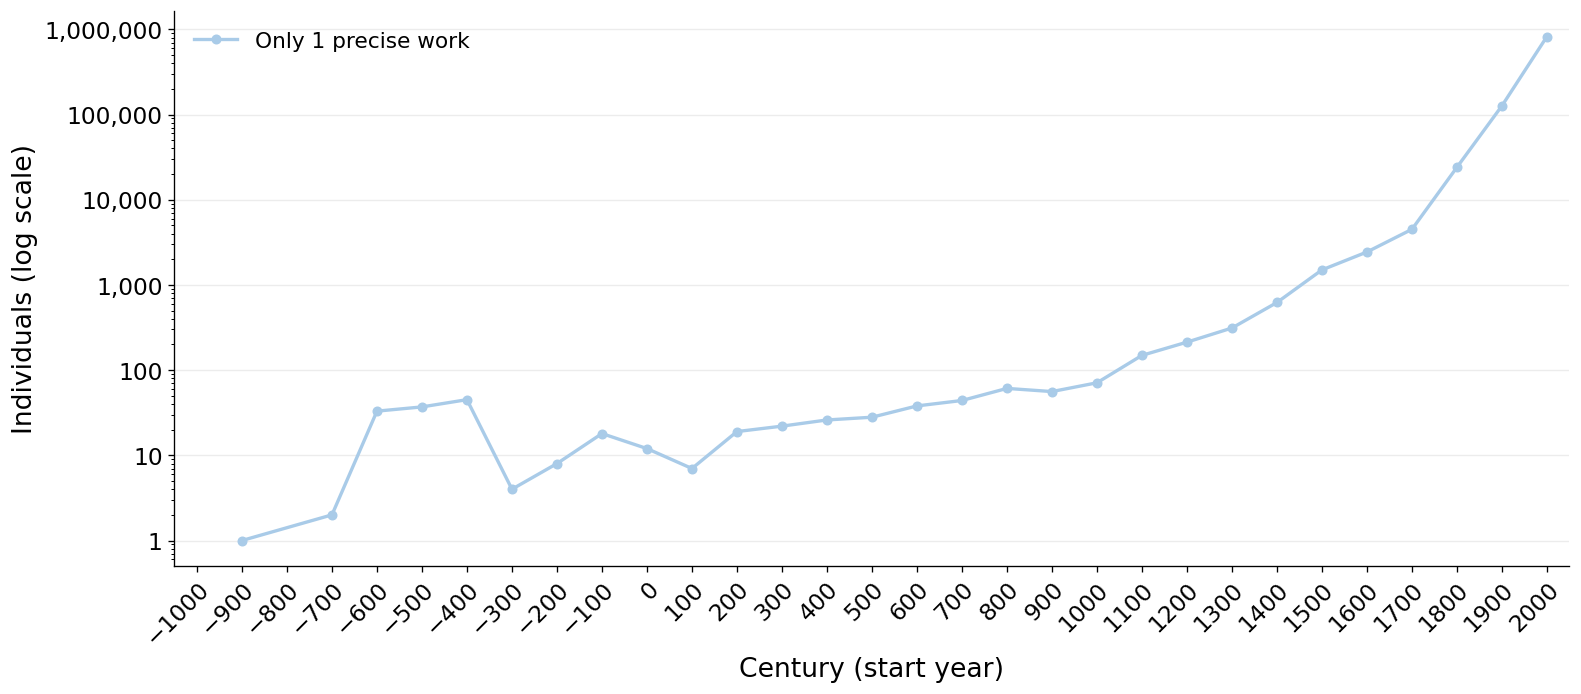

In [15]:
plot_centuries({'Only 1 precise work': one_work_century})

## 3. Both groups together
Individuals with at least one precise work are the two groups above added together; each is placed at the century of their first precise work.

In [16]:
one_or_more_century = (
    two_precise_century.join(one_work_century, on='century_start', how='full', coalesce=True, suffix='_one')
    .fill_null(0)
    .select('century_start', (pl.col('individuals') + pl.col('individuals_one')).alias('individuals'))
    .sort('century_start')
)
assert one_or_more_century['individuals'].sum() == two_precise_century['individuals'].sum() + one_work_century['individuals'].sum()

### Figure: individuals with at least one work with a precise date, by century

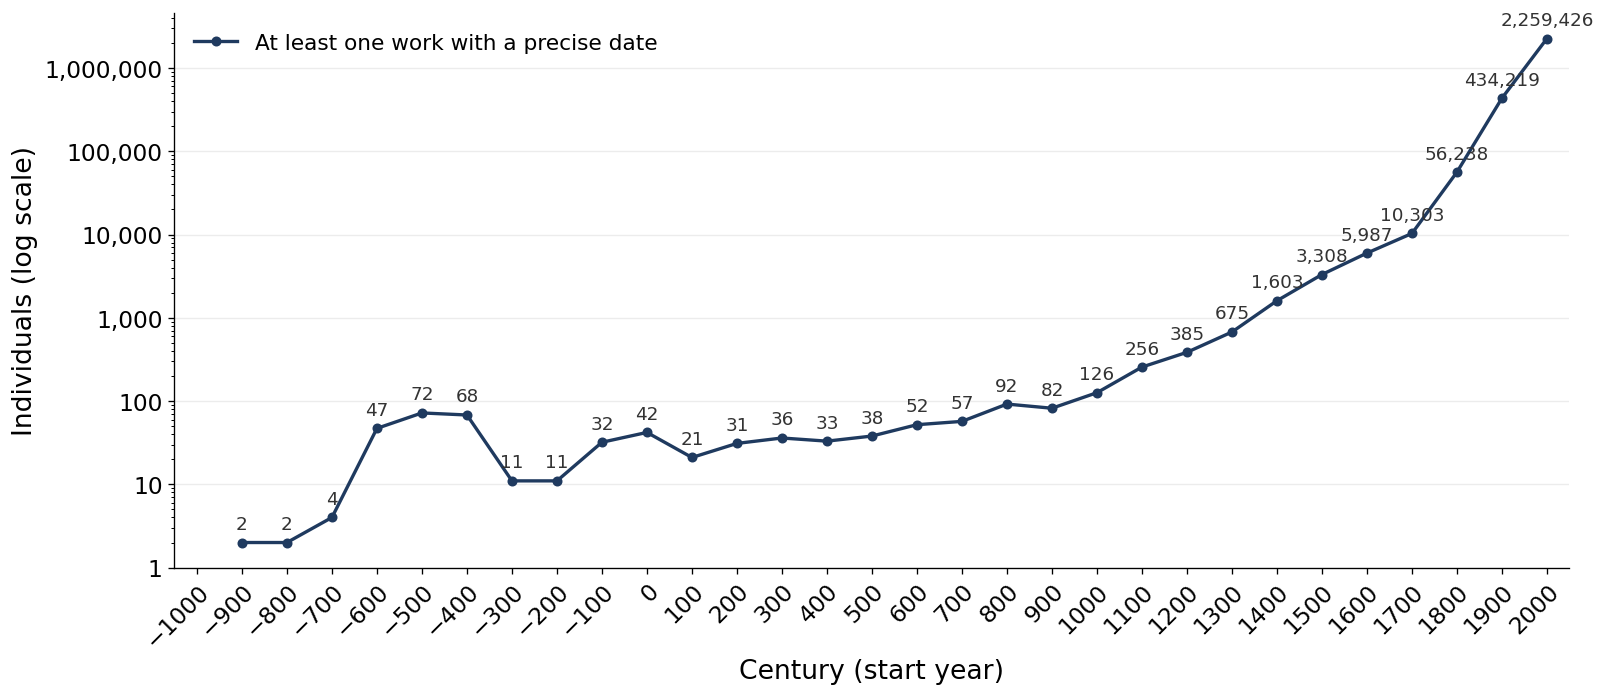

In [17]:
plot_centuries({'At least one work with a precise date': one_or_more_century}, labelled=['At least one work with a precise date'])

### Figure: individuals with dated works, by century

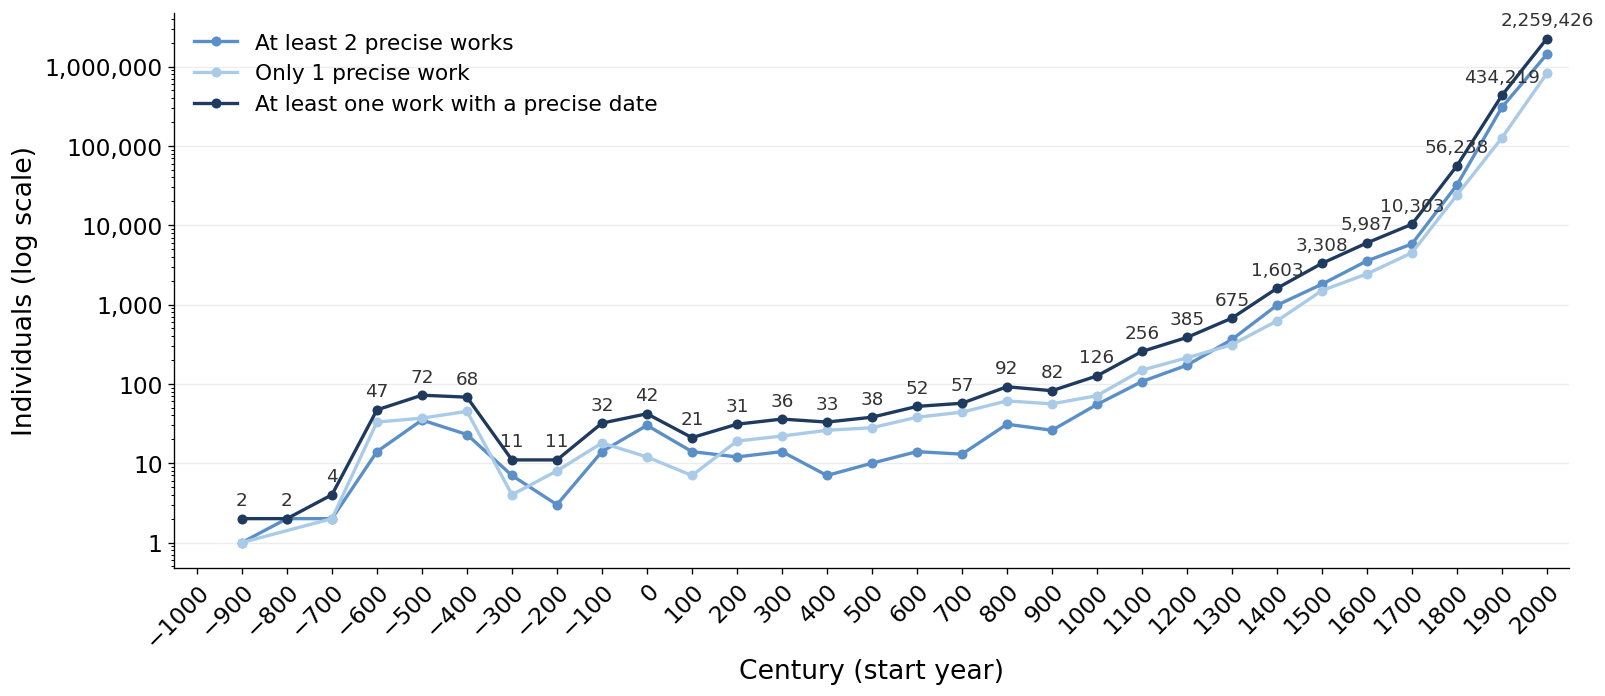

In [18]:
plot_centuries({
    'At least 2 precise works': two_precise_century,
    'Only 1 precise work': one_work_century,
    'At least one work with a precise date': one_or_more_century,
}, labelled=['At least one work with a precise date'])

### Table: individuals with dated works, by century
The total row also counts individuals placed outside 1000 BCE – 2099.

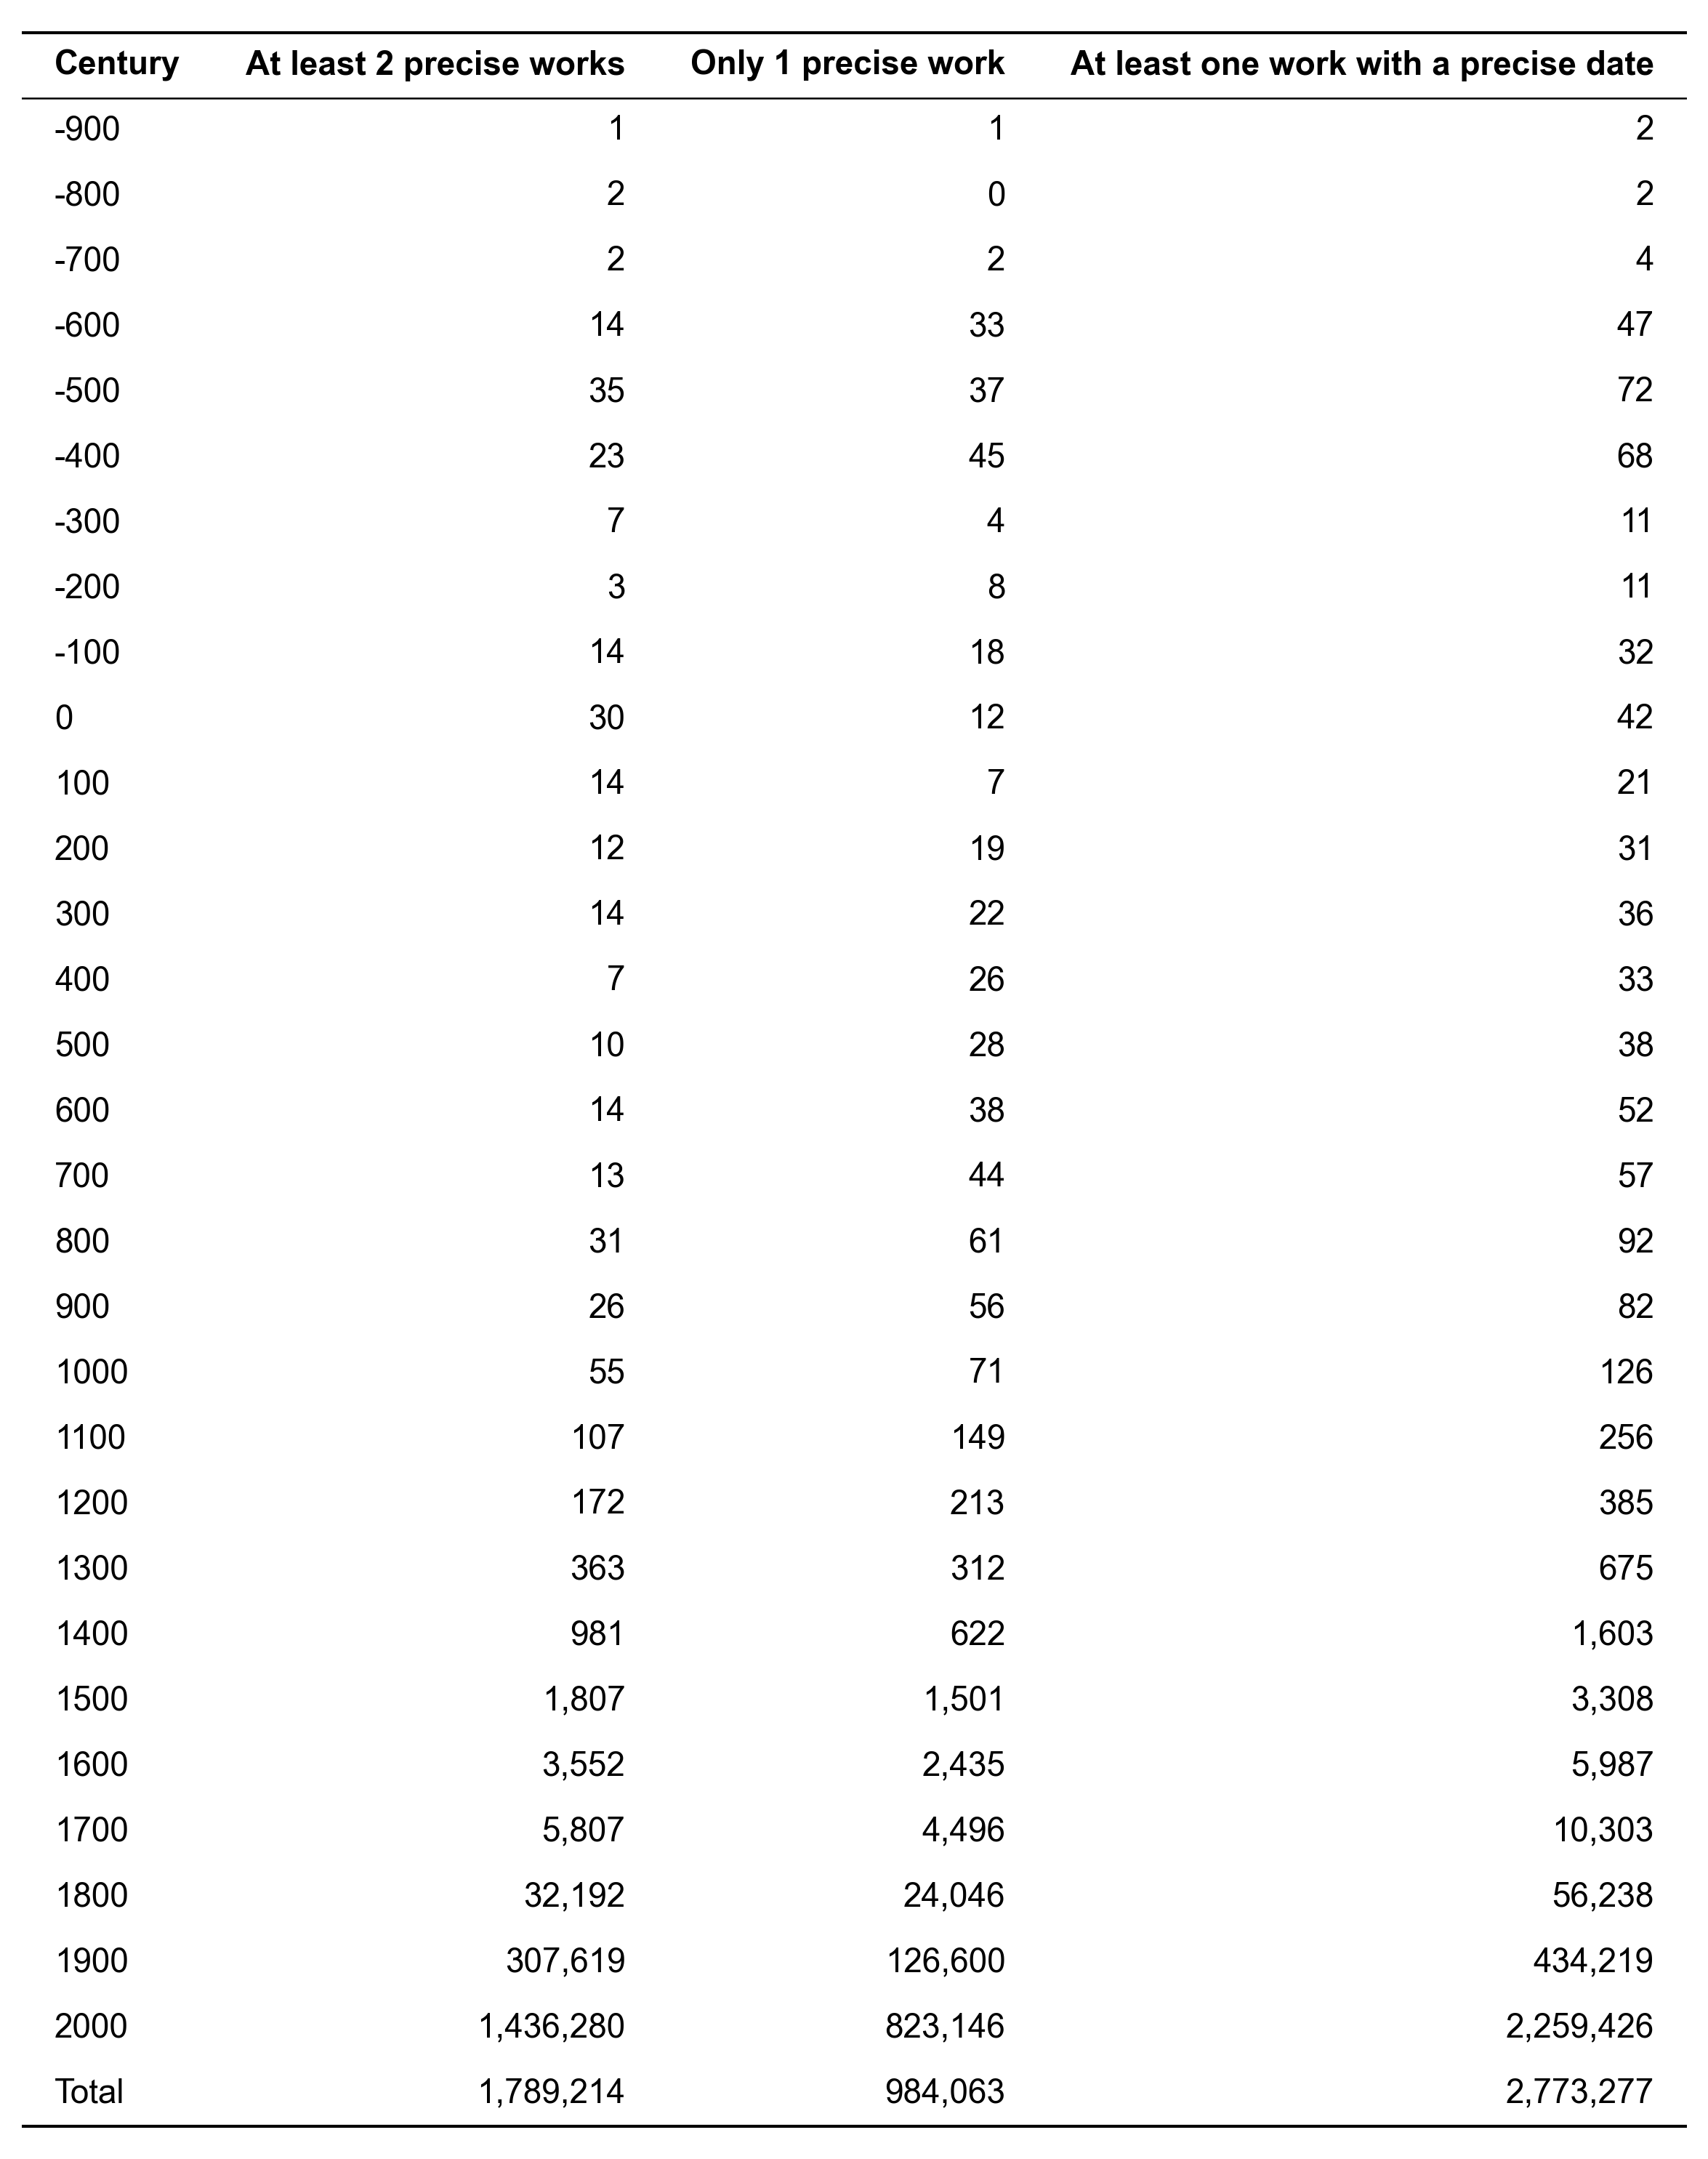

In [19]:
summary = (
    two_precise_century.rename({'individuals': 'At least 2 precise works'})
    .join(one_work_century.rename({'individuals': 'Only 1 precise work'}), on='century_start', how='full', coalesce=True)
    .join(one_or_more_century.rename({'individuals': 'At least one work with a precise date'}), on='century_start', how='full', coalesce=True)
    .fill_null(0)
    .sort('century_start')
    .with_columns(pl.col('century_start').cast(pl.String))
    .rename({'century_start': 'Century'})
)
total_row = pl.DataFrame({
    'Century': ['Total'],
    'At least 2 precise works': [two_precise.height],
    'Only 1 precise work': [one_work.height],
    'At least one work with a precise date': [two_precise.height + one_work.height],
})
show_table(pl.concat([summary, total_row], how='vertical_relaxed'))

## 4. Cleaned work dates
To use works as a proxy for when an individual was active, two cleanups are applied, on dates precise to the year or decade only:

1. Individuals whose dated works all have a publication date only, and who have no birth or death date, are left out: a publication date can refer to a book published long after the author lived.
2. A work date is removed when it is at odds with the individual's life. With a birth or death date, the work must fall between birth and death (birth + 100 or death − 100 when only one is known); this applies to inception dates too. Without them, a publication date must lie within 100 years of the individual's earliest inception date.

A work with both dates keeps its inception.

In [20]:
LIFETIME_LIMIT = 100

connection.execute(f'''
    CREATE OR REPLACE TEMP TABLE clean_work AS
    WITH lifetime AS (
        SELECT entity.qid AS qid,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS birth_year,
               list_min([date.year FOR date IN death_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS death_year
        FROM individual
    ),
    dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               CASE WHEN work.inception.precision IN ('day', 'month', 'year', 'decade') THEN work.inception.year END AS inception_year,
               CASE WHEN work.publication_date.precision IN ('day', 'month', 'year', 'decade') THEN work.publication_date.year END AS publication_year
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    dated_with_source AS (
        SELECT qid, work_qid,
               coalesce(inception_year, publication_year) AS year,
               CASE WHEN inception_year IS NOT NULL THEN 'inception' ELSE 'publication' END AS source
        FROM dated
        WHERE coalesce(inception_year, publication_year) IS NOT NULL
    ),
    first_inception AS (
        SELECT qid, min(year) AS first_inception_year
        FROM dated_with_source
        WHERE source = 'inception'
        GROUP BY qid
    )
    SELECT dated_with_source.*, lifetime.birth_year, lifetime.death_year
    FROM dated_with_source
    JOIN lifetime ON lifetime.qid = dated_with_source.qid
    LEFT JOIN first_inception ON first_inception.qid = dated_with_source.qid
    WHERE (first_inception.qid IS NOT NULL OR lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL)
      AND CASE
          WHEN lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL THEN
              dated_with_source.year BETWEEN coalesce(lifetime.birth_year, lifetime.death_year - {LIFETIME_LIMIT})
                                         AND coalesce(lifetime.death_year, lifetime.birth_year + {LIFETIME_LIMIT})
          WHEN dated_with_source.source = 'publication' THEN
              abs(dated_with_source.year - first_inception.first_inception_year) <= {LIFETIME_LIMIT}
          ELSE TRUE
      END
''')
clean_counts = connection.execute('''
    SELECT count(DISTINCT qid) AS individuals, count(*) AS work_dates,
           count(*) FILTER (WHERE source = 'inception') AS inception_dates
    FROM clean_work
''').pl()
print(f"{clean_counts['individuals'][0]:,} individuals keep at least one work date "
      f"(against {works.filter(pl.col('precise_works') >= 1).height:,} before cleaning)")
print(f"{clean_counts['work_dates'][0]:,} work dates kept, {clean_counts['inception_dates'][0]:,} of them inception dates")

584,939 individuals keep at least one work date (against 2,773,277 before cleaning)
9,481,861 work dates kept, 855,134 of them inception dates


### One example per century, cleaned work dates
The individual with the most Wikimedia pages among those with at least two cleaned works whose first cleaned work falls in the century, with their birth and death, their number of cleaned works, and their first and last cleaned works; the span is the years between the two. Each individual and work is followed by its Wikidata id in brackets; the source of each work date is given after its year. Works without a title are shown as "(untitled)". Individuals listed in `EXTRA_INDIVIDUALS` (Tycho Brahe) are added as an extra row in their century.

30 centuries with an example


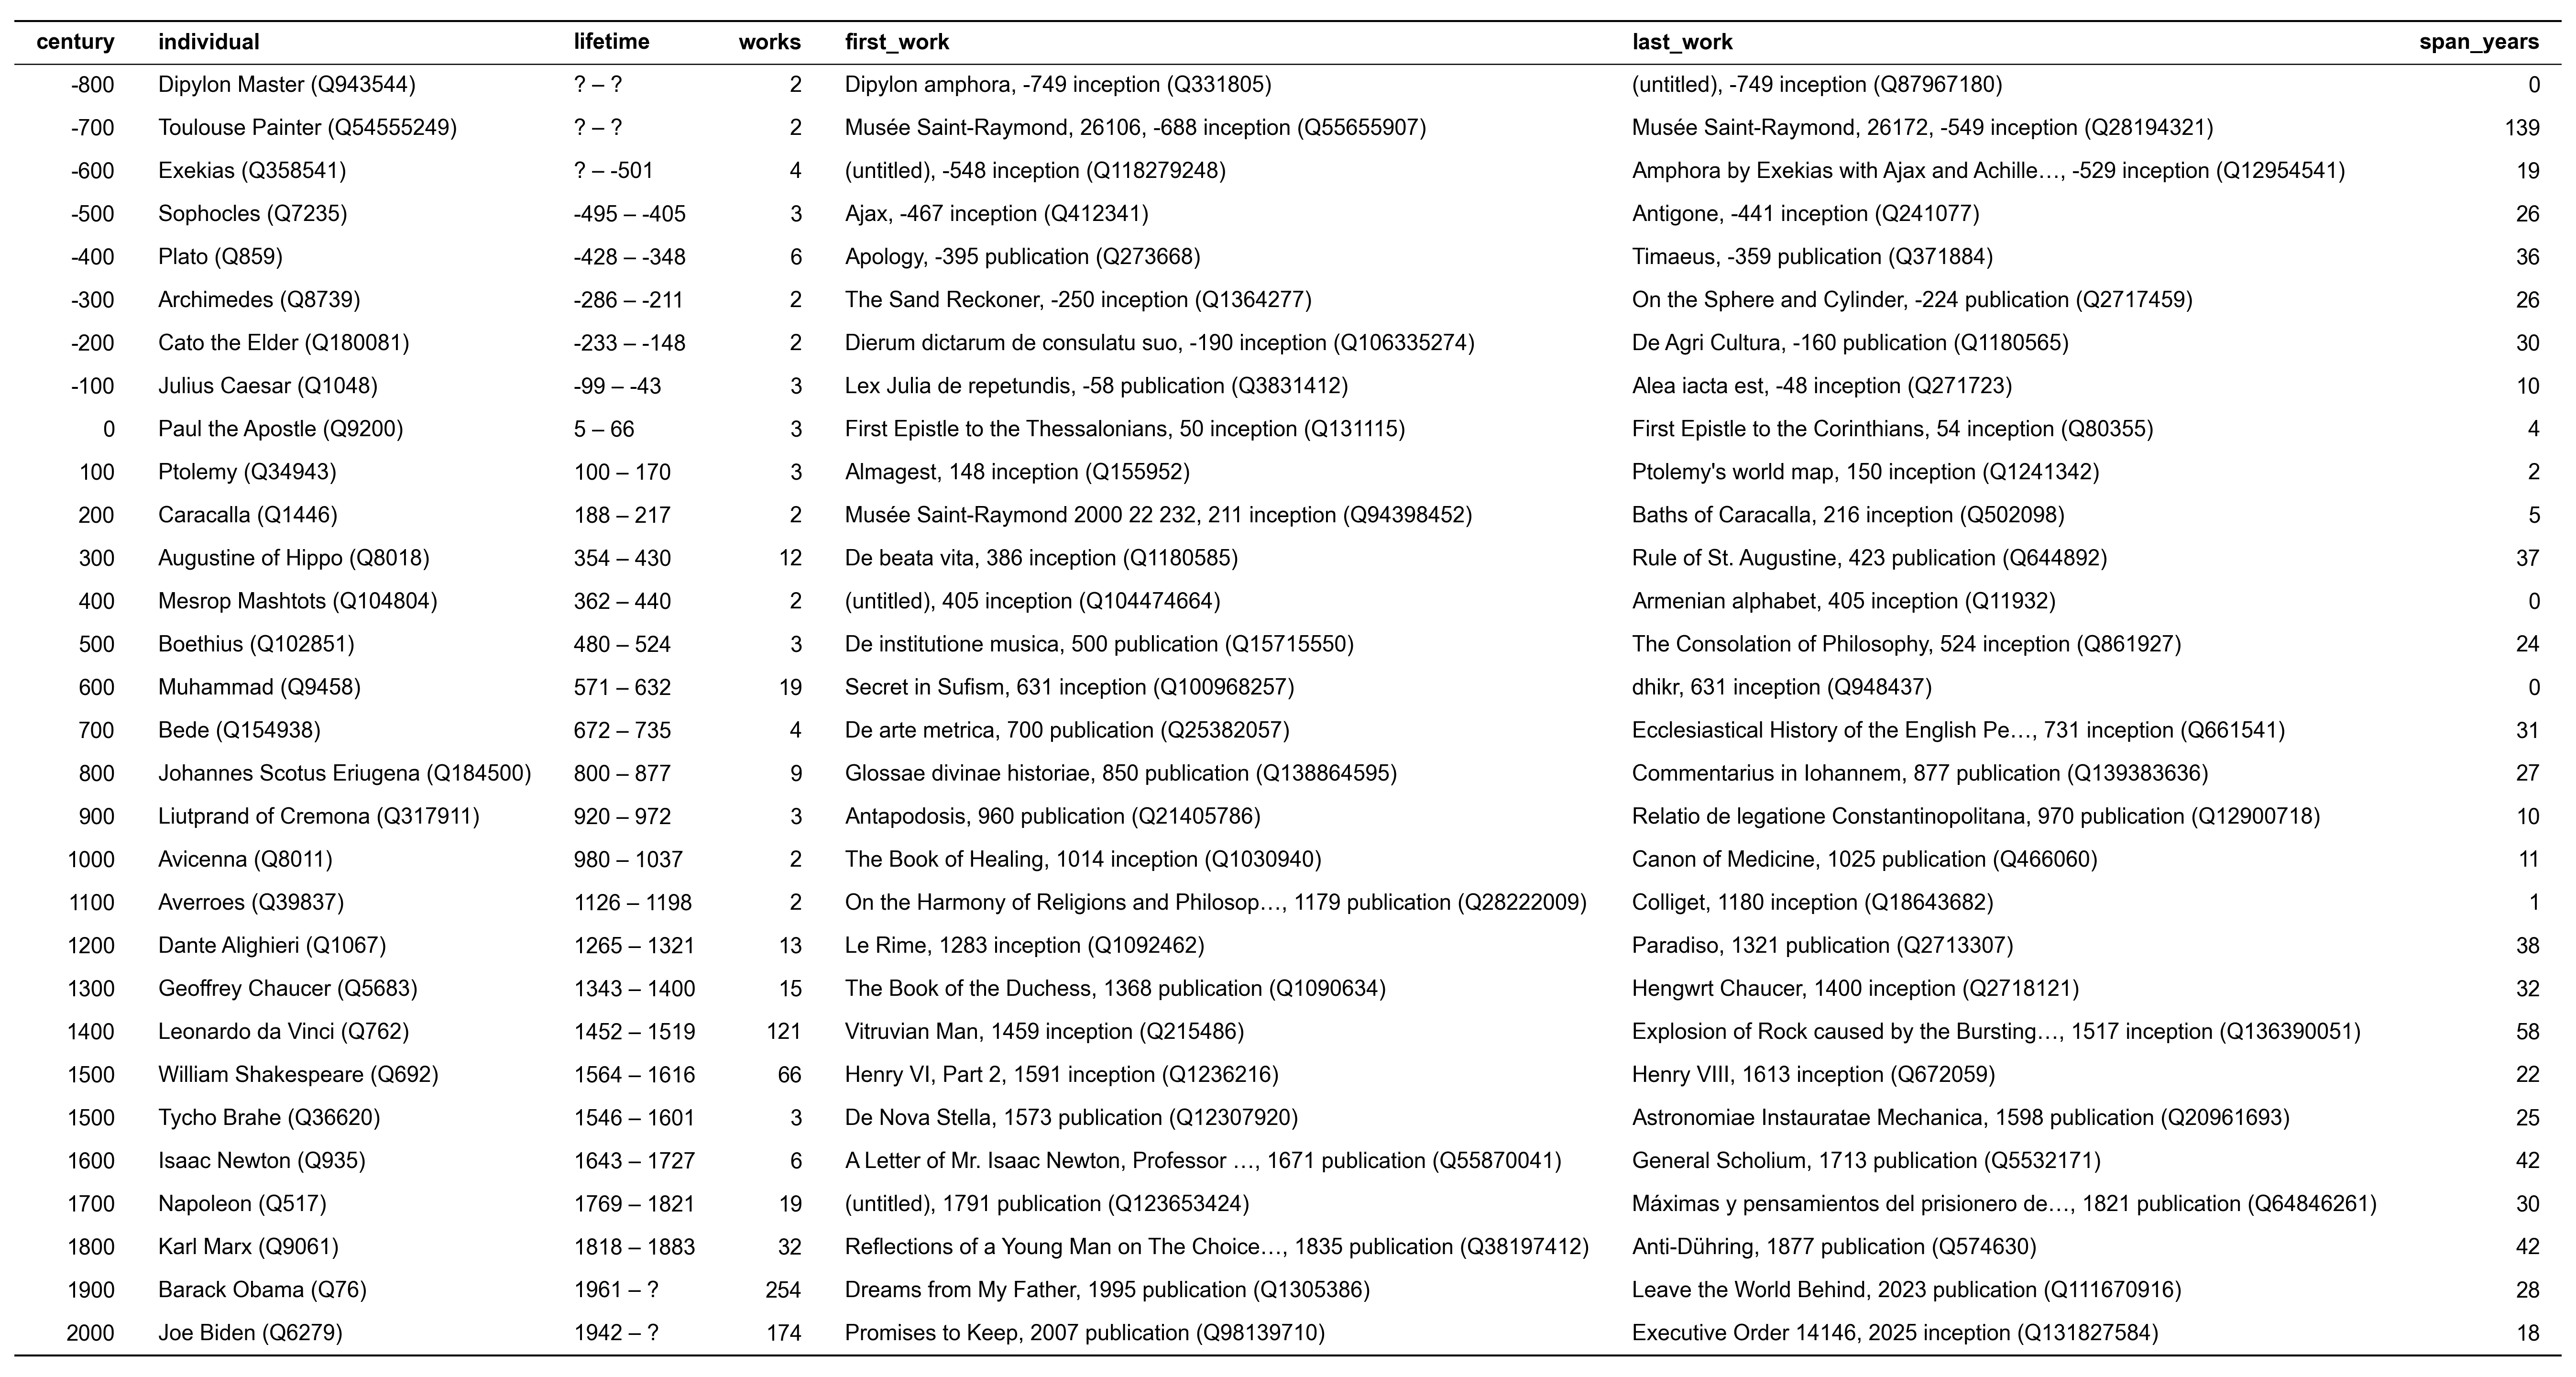

In [21]:
EXTRA_INDIVIDUALS = ['Q36620']
extra_sql = "', '".join(EXTRA_INDIVIDUALS)

clean_examples = connection.execute(f'''
    WITH placed AS (
        SELECT qid, floor(min(year) / 100)::BIGINT * 100 AS century_start
        FROM clean_work
        GROUP BY qid
        HAVING count(*) >= 2
    ),
    best AS (
        SELECT placed.century_start, placed.qid,
               coalesce(individual.entity.label_en, individual.entity.label_non_en) || ' (' || placed.qid || ')' AS individual
        FROM placed
        JOIN individual ON individual.entity.qid = placed.qid
        WHERE placed.century_start BETWEEN {FIRST_CENTURY} AND {LAST_CENTURY}
        QUALIFY row_number() OVER (PARTITION BY placed.century_start ORDER BY len(individual.sitelink) DESC, placed.qid) = 1
              OR placed.qid IN ('{extra_sql}')
    ),
    ranked AS (
        SELECT best.century_start, best.qid, best.individual, clean_work.year,
               coalesce(clean_work.birth_year::VARCHAR, '?') || ' – ' || coalesce(clean_work.death_year::VARCHAR, '?') AS lifetime,
               CASE WHEN length(coalesce(work.entity.label_en, work.entity.label_non_en, '(untitled)')) > 40
                    THEN left(coalesce(work.entity.label_en, work.entity.label_non_en), 40) || '…'
                    ELSE coalesce(work.entity.label_en, work.entity.label_non_en, '(untitled)') END
                   || ', ' || clean_work.year || ' ' || clean_work.source || ' (' || clean_work.work_qid || ')' AS work,
               row_number() OVER (PARTITION BY best.qid ORDER BY clean_work.year, clean_work.work_qid) AS from_first,
               row_number() OVER (PARTITION BY best.qid ORDER BY clean_work.year DESC, clean_work.work_qid DESC) AS from_last,
               count(*) OVER (PARTITION BY best.qid) AS clean_works
        FROM best
        JOIN clean_work ON clean_work.qid = best.qid
        JOIN work ON work.entity.qid = clean_work.work_qid
    )
    SELECT century_start AS century, qid, individual, max(lifetime) AS lifetime, max(clean_works) AS works,
           max(work) FILTER (WHERE from_first = 1) AS first_work,
           max(work) FILTER (WHERE from_last = 1 AND clean_works > 1) AS last_work,
           max(year) FILTER (WHERE from_last = 1) - max(year) FILTER (WHERE from_first = 1) AS span_years
    FROM ranked
    GROUP BY century_start, qid, individual
    ORDER BY century_start, qid IN ('{extra_sql}'), individual
''').pl().with_columns(pl.col('century').cast(pl.String)).drop('qid')
print(f'{clean_examples.height} centuries with an example')
show_table(clean_examples)